In [14]:
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages

load_dotenv()

True

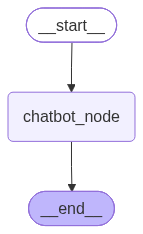

In [15]:
llm = init_chat_model(model="gpt-4o-mini", temperature=0)

class State(TypedDict):
    messages: Annotated[list, add_messages]

def chatbot(state: State) -> State:
    return {"messages": [llm.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("chatbot_node", chatbot)
builder.add_edge(START, "chatbot_node")
builder.add_edge("chatbot_node", END)

graph = builder.compile()

from IPython.display import Image, display

Image(graph.get_graph().draw_mermaid_png())


In [17]:
message = [{"role": "user", "content": "Hello, how are you?"}, {"role": "user", "content": "Do you know who was the first person to walk on the moon?"}]
for i in message:
    response = graph.invoke({"messages": [i]})
    print(response)

{'messages': [HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='1cb7fc37-44df-43f9-b3c8-1385ff8a9647'), AIMessage(content="Hello! I'm just a program, so I don't have feelings, but I'm here and ready to help you. How can I assist you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 13, 'total_tokens': 42, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_a71b930f7c', 'id': 'chatcmpl-EeJhjXhFTrvkWN4X2Zl0ptHEux1lC', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a187ac-2ecd-745c-807d-08cbdece8764-0', t

In [ ]:
state = None
while True:
    in_message = input("You: ")
    if in_message.lower() in ["exit", "quit"]:
        break

    if in_message.lower() in ["clear", "reset"]:
        state = None
        continue

    if state is None:
        state = {"messages": [{"role": "user", "content": in_message}]}
    else:
        state["messages"].append({"role": "user", "content": in_message})

    state = graph.invoke(state)
    print("Bot: ", state["messages"][-1].content)


Bot:  Hello! How can I assist you today?


OpenAIInvalidRequestError: Error code: 400 - Missing required parameter: 'messages[2].content[0].type'.